In [ ]:
%cd /content
!git clone https://github.com/alonhelvits/SB-ECC.git
%cd /content/SB-ECC


Clone the SB-ECC Repository

This cell downloads the original SB-ECC implementation from GitHub into /content/SB-ECC and sets it as the working directory for dependency installation, training, and evaluation.

In [ ]:
!pip install -r requirements.txt

Install Dependencies

This cell installs the Python dependencies listed in requirements.txt to prepare the environment for SB-ECC training and evaluation.

In [ ]:
!ls -lah /content/SB-ECC

Check Repository Files

This cell lists the files and folders in /content/SB-ECC, including their sizes and permissions, to verify the repository contents.

In [ ]:
!python Main.py \
    --gpus=0 \
    --code_type=LDPC \
    --code_n=49 \
    --code_k=24 \
    --N_dec=6 \
    --d_model=128 \
    --h=8 \
    --lr=0.0005 \
    --batch_size=256 \
    --test_batch_size=2048 \
    --epochs=1500 \
    --solver=euler \
    --sigma_max=0.8 \
    --sigma_min=0.1

Train SB-ECC on LDPC(49,24)

This cell trains an SB-ECC decoder for LDPC(49,24) on GPU 0 for 1,500 epochs, using 6 decoder layers, a hidden dimension of 128, 8 attention heads, a learning rate of 5e-4, and a training batch size of 256. The noise range is set to sigma_min=0.1 and sigma_max=0.8. Evaluation uses the Euler solver with a test batch size of 2,048. Training logs and checkpoints are saved under SB_ECC_Results.

In [ ]:
!python Main.py \
    --gpus=0 \
    --code_type=BCH \
    --code_n=63 \
    --code_k=45 \
    --N_dec=6 \
    --d_model=128 \
    --h=8 \
    --lr=0.0005 \
    --batch_size=256 \
    --test_batch_size=2048 \
    --epochs=1500 \
    --solver=euler \
    --sigma_max=0.8 \
    --sigma_min=0.1

Train SB-ECC on BCH(63,45)

This cell trains an SB-ECC decoder for BCH(63,45) on GPU 0 for 1,500 epochs, using 6 decoder layers, a hidden dimension of 128, 8 attention heads, a learning rate of 5e-4, and a training batch size of 256. The noise range is set to sigma_min=0.1 and sigma_max=0.8. Evaluation uses the Euler solver with a test batch size of 2,048. Training logs and checkpoints are saved under SB_ECC_Results.

In [ ]:
!python Main.py \
    --gpus=0 \
    --code_type=LDPC \
    --code_n=121 \
    --code_k=80 \
    --N_dec=6 \
    --d_model=128 \
    --h=8 \
    --lr=0.0005 \
    --batch_size=128 \
    --test_batch_size=2048 \
    --epochs=1500 \
    --solver=euler \
    --sigma_max=0.8 \
    --sigma_min=0.1

Train SB-ECC on LDPC(121,80)

This cell trains an SB-ECC decoder for LDPC(121,80) on GPU 0 for 1,500 epochs, using 6 decoder layers, a hidden dimension of 128, 8 attention heads, a learning rate of 5e-4, and a training batch size of 128. The noise range is set to sigma_min=0.1 and sigma_max=0.8. Evaluation uses the Euler solver with a test batch size of 2,048. Training logs and checkpoints are saved under SB_ECC_Results.

In [ ]:
!python Main.py \
    --gpus=0 \
    --code_type=MACKAY \
    --code_n=96 \
    --code_k=48 \
    --N_dec=6 \
    --d_model=128 \
    --h=8 \
    --lr=0.0005 \
    --batch_size=256 \
    --test_batch_size=2048 \
    --epochs=1500 \
    --solver=euler \
    --sigma_max=0.8 \
    --sigma_min=0.1

###  Training MacKay (96,48)

We train the SB-ECC model on the MacKay(96,48) code for 1,500 epochs with a batch size of 256 and a learning rate of 5×10⁻⁴. The model uses 6 decoder layers, a hidden dimension of 128, and 8 attention heads. The Euler solver is configured with σ_max = 0.8 and σ_min = 0.1.

In [ ]:
!python Main.py \
    --gpus=0 \
    --code_type=CCSDS \
    --code_n=128 \
    --code_k=64 \
    --N_dec=6 \
    --d_model=128 \
    --h=8 \
    --lr=0.0005 \
    --batch_size=256 \
    --test_batch_size=2048 \
    --epochs=1500 \
    --solver=euler \
    --sigma_max=0.8 \
    --sigma_min=0.1

###  Training CCSDS (128,64)

We train the SB-ECC model on the CCSDS(128,64) code for 1,500 epochs with a batch size of 256 and a learning rate of 5×10⁻⁴. The model uses 6 decoder layers, a hidden dimension of 128, and 8 attention heads. The Euler solver is configured with σ_max = 0.8 and σ_min = 0.1.

In [ ]:
import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/content/SB-ECC")
RESULTS = ROOT / "SB_ECC_Results"
LOG_DIR = ROOT / "test_logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(ROOT)

models = [
    ("LDPC", 49, 24, "LDPC49-24"),
    ("BCH", 63, 45, "BCH63-45"),
    ("LDPC", 121, 80, "LDPC121-80"),
]

all_weights = [
    p for p in RESULTS.rglob("*")
    if p.is_file() and p.name.startswith("best_model")
]

for code_type, n, k, label in models:

    key = f"{code_type.lower()}__code_n_{n}_k_{k}__"

    matches = [
        p for p in all_weights
        if key in str(p).lower()
    ]

    if not matches:
        aliases = {
            "LDPC49-24": ["best_model_ldpc49-24"],
            "BCH63-45": ["best_model_bch63-45"],
            "LDPC121-80": ["best_model_ldpc121-80"],
        }

        matches = [
            p for p in all_weights
            if p.name.lower() in aliases.get(label, [])
        ]

    if not matches:
        raise FileNotFoundError(
            f"Checkpoint not found: {label}"
        )

    weight = max(
        matches,
        key=lambda p: p.stat().st_mtime
    )

    print(f"\n[Model] {label}")
    print(f"[Checkpoint] {weight}", flush=True)

    # LDPC121-80: 6 dB capped at 100 million
    if label == "LDPC121-80":
        test_runs = [
            ("2,6", None),
            ("6", 100000000),
        ]
    else:
        test_runs = [
            ("2,7", None),
        ]

    # Keep original log filename
    log_path = LOG_DIR / f"{label}_paper.log"

    with open(log_path, "w") as log:

        for ebno_range, max_samples in test_runs:

            print(
                f"\n[Testing] {label}, Eb/N0={ebno_range}",
                flush=True
            )

            cmd = [
                sys.executable, "-u", "inference.py",
                "--model_path", str(weight),
                "--code_type", code_type,
                "--code_n", str(n),
                "--code_k", str(k),
                "--solver", "euler",
                "--num_steps", "10",
                "--ebno_range", ebno_range,
                "--test_batch_size", "2048",
                "--workers", "0",
                "--seed", "42",
            ]

            if max_samples is not None:
                cmd += [
                    "--max_samples", str(max_samples)
                ]

            log.write(
                f"\n===== {label} Eb/N0={ebno_range} "
                f"max_samples={max_samples} =====\n"
            )
            log.flush()

            process = subprocess.Popen(
                cmd,
                stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT,
                text=True,
                bufsize=1
            )

            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()

            return_code = process.wait()

            if return_code != 0:
                raise RuntimeError(
                    f"{label} failed. See {log_path}"
                )

    print(f"\n[Completed] {label}")
    print(f"[Log] {log_path}")

print("\nAll three model evaluations completed.")

Evaluate the Three Trained Models

This cell automatically locates the most recently modified matching checkpoint for LDPC(49,24), BCH(63,45), and LDPC(121,80), then evaluates each model at Eb/N0 values from 2 to 6 dB using the Euler solver with 10 steps, a test batch size of 2,048, and a random seed of 42. For LDPC(121,80), the 6 dB evaluation runs separately with a sample limit of 100 million. Evaluation output, including BER and FER (BLER), is displayed in real time and saved to a separate log file for each model under test_logs.

In [ ]:
import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/content/SB-ECC")
RESULTS = ROOT / "SB_ECC_Results"
LOG_DIR = ROOT / "test_logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(ROOT)

models = [
    (
        "MACKAY", 96, 48, "MACKAY96-48",
        RESULTS / "MACKAY__Code_n_96_k_48__02_11_2026_11_18_45" / "best_model"
    ),
    (
        "CCSDS", 128, 64, "CCSDS128-64",
        RESULTS / "CCSDS__Code_n_128_k_64__03_11_2026_00_56_38" / "best_model"
    ),
]

for code_type, n, k, label, weight in models:

    if not weight.is_file():
        raise FileNotFoundError(
            f"Checkpoint not found: {weight}"
        )

    print(f"\n[Model] {label}")
    print(f"[Checkpoint] {weight}", flush=True)

    # 2,3,4,5,6 dB
    # Paper Table 1 uses 4,5,6 dB
    ebno_range = "2,7"

    # Separate log for each model
    log_path = LOG_DIR / f"{label}_paper.log"

    print(
        f"\n[Testing] {label}, Eb/N0={ebno_range}",
        flush=True
    )

    cmd = [
        sys.executable, "-u", "inference.py",
        "--model_path", str(weight),
        "--code_type", code_type,
        "--code_n", str(n),
        "--code_k", str(k),
        "--solver", "euler",
        "--num_steps", "10",
        "--ebno_range", ebno_range,
        "--test_batch_size", "2048",
        "--workers", "0",
        "--gpus", "0",
        "--seed", "42",
    ]

    # Paper protocol:
    # More than 500 frame errors
    # Minimum 100,000 frames
    # Maximum 100,000,000 frames
    # Do NOT pass --max_samples

    with open(log_path, "w", buffering=1) as log:

        log.write(
            f"===== {label} =====\n"
            f"Eb/N0={ebno_range}\n"
            f"Solver=euler\n"
            f"Steps=10\n"
            f"Maximum frames=100000000\n"
            f"Frame error threshold=500\n\n"
        )

        process = subprocess.Popen(
            cmd,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1
        )

        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)

        return_code = process.wait()

        if return_code != 0:
            raise RuntimeError(
                f"{label} failed. See {log_path}"
            )

    print(f"\n[Completed] {label}")
    print(f"[Log] {log_path}")

print("\nBoth model evaluations completed.")

We evaluate the trained MacKay(96,48) and CCSDS(128,64) models following the SB-ECC paper's evaluation protocol. Both models use the Euler solver with 10 inference steps and are tested over an Eb/N0 range of 2–6 dB. Each evaluation continues until more than 500 frame errors are accumulated after at least 100,000 tested frames, or a maximum of 100 million frames is reached. The results are reported using BER, BLER, and −ln(BER) for comparison with the original paper.


LDPC(49,24)
Eb/N0=2 dB, BER=2.45667897e-02
Eb/N0=3 dB, BER=5.49168955e-03
Eb/N0=4 dB, BER=6.13358207e-04
Eb/N0=5 dB, BER=2.77628131e-05
Eb/N0=6 dB, BER=5.44684105e-07

BCH(63,45)
Eb/N0=2 dB, BER=3.56606670e-02
Eb/N0=3 dB, BER=1.06158076e-02
Eb/N0=4 dB, BER=1.61558309e-03
Eb/N0=5 dB, BER=1.15980644e-04
Eb/N0=6 dB, BER=2.81554963e-06

LDPC(121,80)
Eb/N0=2 dB, BER=3.03004487e-02
Eb/N0=3 dB, BER=4.57497035e-03
Eb/N0=4 dB, BER=1.66270351e-04
Eb/N0=5 dB, BER=1.09928837e-06
Eb/N0=6 dB, BER=1.57021968e-09


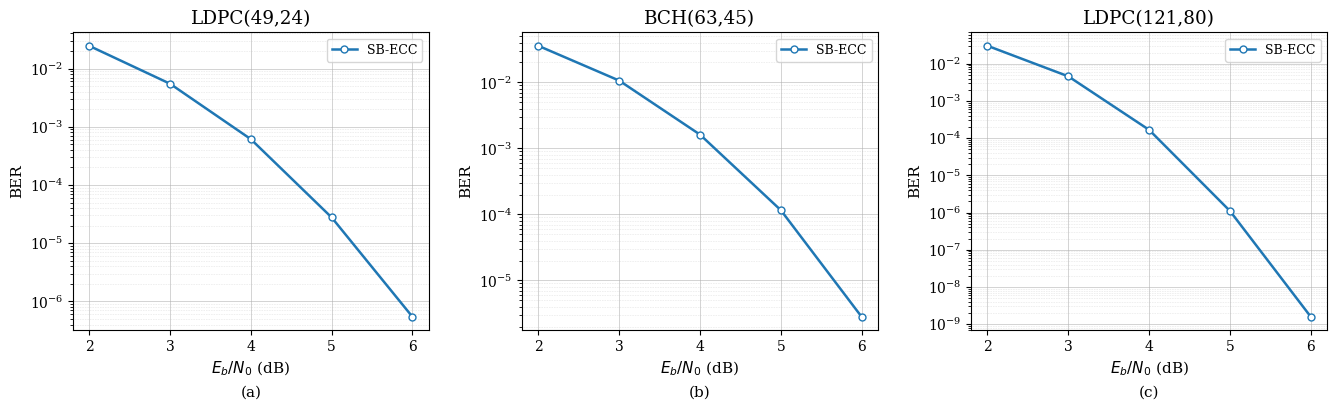


Figures saved:
/content/SB-ECC/figures/SB_ECC_BER_Comparison.png
/content/SB-ECC/figures/SB_ECC_BER_Comparison.pdf


In [ ]:
import re
import ast
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Paths
# ============================================================
ROOT = Path("/content/SB-ECC")
LOG_DIR = ROOT / "test_logs"
SAVE_DIR = ROOT / "figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

models = [
    ("LDPC(49,24)", "LDPC49-24_paper.log"),
    ("BCH(63,45)", "BCH63-45_paper.log"),
    ("LDPC(121,80)", "LDPC121-80_paper.log"),
]

NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"


# ============================================================
# 2. Locate log files
# ============================================================
def resolve_log_path(filename):
    exact_path = LOG_DIR / filename

    if exact_path.is_file():
        return exact_path

    stem = Path(filename).stem
    suffix = Path(filename).suffix

    # Support filenames with one or more download suffixes:
    # xxx(1).log, xxx (1).log, xxx(1) (2).log
    candidates = sorted(
        path
        for path in LOG_DIR.glob(f"{stem}*{suffix}")
        if path.is_file()
        and re.fullmatch(
            rf"{re.escape(stem)}(?:\s*\(\d+\))*{re.escape(suffix)}",
            path.name
        )
    )

    if len(candidates) == 1:
        print(f"Reading: {candidates[0]}")
        return candidates[0]

    if len(candidates) > 1:
        raise RuntimeError(
            f"Multiple files match {filename}:\n"
            + "\n".join(str(path) for path in candidates)
            + f"\nRename the intended file to {filename}."
        )

    raise FileNotFoundError(f"Log file not found: {exact_path}")


# ============================================================
# 3. Parse numeric values
# ============================================================
def parse_last_value(raw):
    clean = re.sub(
        r"np\.float(?:16|32|64)\(\s*([^()]*)\s*\)",
        r"\1",
        raw.strip()
    )

    value = ast.literal_eval(clean)

    if isinstance(value, (list, tuple)):
        if not value:
            raise ValueError("Empty numeric list")
        value = value[-1]

    return float(value)


# ============================================================
# 4. Read BER records
# ============================================================
def parse_ber_log(log_path):
    text = Path(log_path).read_text(
        encoding="utf-8",
        errors="replace"
    )

    summary = {}
    test_records = {}
    supplementary_records = {}

    for line_number, line in enumerate(text.splitlines(), start=1):
        line = line.strip()

        # Rounded summary:
        # Test BER 2: 3.03e-02 3: 4.57e-03 ...
        if line.startswith("Test BER "):
            pairs = re.findall(
                rf"({NUMBER})\s*:\s*({NUMBER})",
                line[len("Test BER "):]
            )

            for snr, ber in pairs:
                summary[float(snr)] = float(ber)

            continue

        # Support Test, PaperReference and Paper record prefixes.
        record_match = re.match(
            rf"^(Test|PaperReference|Paper)\s+"
            rf"EbN0\s*=\s*({NUMBER})\s*,",
            line
        )

        if not record_match:
            continue

        # Match BER exactly, excluding BER_DDPM and neg_ln_BER.
        # Support a list, np.float64 scalar or plain numeric scalar.
        ber_match = re.search(
            rf"(?:^|,\s*)BER\s*=\s*"
            rf"(\[[^\]]*\]|"
            rf"np\.float(?:16|32|64)\(\s*{NUMBER}\s*\)|"
            rf"{NUMBER})"
            rf"(?=\s*(?:,|$|#))",
            line
        )

        if not ber_match:
            continue

        try:
            prefix = record_match.group(1)
            snr = float(record_match.group(2))
            ber = parse_last_value(ber_match.group(1))

            if prefix == "Test":
                test_records[snr] = ber
            else:
                supplementary_records[snr] = ber

        except (ValueError, SyntaxError, TypeError, IndexError) as error:
            print(
                f"Cannot parse {Path(log_path).name}, "
                f"line {line_number}: {error}"
            )

    # Prefer precise Test records where the same SNR appears
    # in multiple record formats.
    results = dict(supplementary_records)
    results.update(summary)
    results.update(test_records)

    return {
        snr: ber
        for snr, ber in results.items()
        if np.isfinite(snr)
        and np.isfinite(ber)
        and 0 < ber <= 1
    }


# ============================================================
# 5. Load data
# ============================================================
datasets = []

for model_name, filename in models:
    log_path = resolve_log_path(filename)
    results = parse_ber_log(log_path)

    if not results:
        raise ValueError(f"No valid BER records found in {log_path}")

    points = sorted(results.items())
    datasets.append((model_name, points))

    print(f"\n{model_name}")
    for snr, ber in points:
        print(f"Eb/N0={snr:g} dB, BER={ber:.8e}")


# ============================================================
# 6. Plot
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
    "savefig.dpi": 300,
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(13.5, 4.3)
)

for idx, (model_name, points) in enumerate(datasets):
    ax = axes[idx]
    x, y = zip(*points)

    ax.semilogy(
        x, y,
        color="tab:blue",
        marker="o",
        markersize=5,
        markerfacecolor="white",
        linewidth=1.8,
        linestyle="-",
        label="SB-ECC"
    )

    ax.set_title(model_name)
    ax.set_xlabel(r"$E_b/N_0$ (dB)")
    ax.set_ylabel("BER")

    ax.set_xticks([2, 3, 4, 5, 6])
    ax.set_xlim(1.8, 6.2)

    ax.grid(
        True,
        which="major",
        linestyle="-",
        linewidth=0.6,
        alpha=0.65
    )

    ax.grid(
        True,
        which="minor",
        linestyle=":",
        linewidth=0.45,
        alpha=0.5
    )

    ax.legend(loc="best", frameon=True)

    ax.text(
        0.5, -0.21,
        f"({chr(97 + idx)})",
        transform=ax.transAxes,
        ha="center",
        va="center"
    )

plt.tight_layout(w_pad=2.0)


# ============================================================
# 7. Save
# ============================================================
png_path = SAVE_DIR / "SB_ECC_BER_Comparison.png"
pdf_path = SAVE_DIR / "SB_ECC_BER_Comparison.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nFigures saved:")
print(png_path)
print(pdf_path)


MacKay(96,48)
Eb/N0=2 dB, BER=2.07662783e-02
Eb/N0=3 dB, BER=2.94442736e-03
Eb/N0=4 dB, BER=1.66583430e-04
Eb/N0=5 dB, BER=3.55592945e-06
Eb/N0=6 dB, BER=8.37485000e-08

CCSDS(128,64)
Eb/N0=2 dB, BER=4.42011308e-02
Eb/N0=3 dB, BER=8.35667824e-03
Eb/N0=4 dB, BER=5.15762641e-04
Eb/N0=5 dB, BER=8.39626666e-06
Eb/N0=6 dB, BER=5.49208908e-08


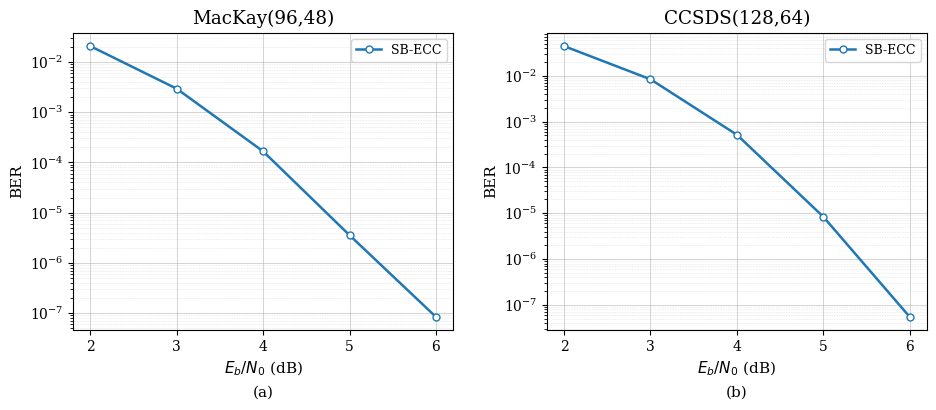


Figures saved:
/content/SB-ECC/figures/SB_ECC_MACKAY_CCSDS_BER.png
/content/SB-ECC/figures/SB_ECC_MACKAY_CCSDS_BER.pdf


In [7]:
import re
import ast
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Paths
# ============================================================
ROOT = Path("/content/SB-ECC")
LOG_DIR = ROOT / "test_logs"
SAVE_DIR = ROOT / "figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

models = [
    ("MacKay(96,48)", "MACKAY96-48_paper.log"),
    ("CCSDS(128,64)", "CCSDS128-64_paper.log"),
]

NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"


# ============================================================
# 2. Locate log files
# ============================================================
def resolve_log_path(filename):

    exact_path = LOG_DIR / filename

    if exact_path.is_file():
        return exact_path

    stem = Path(filename).stem
    suffix = Path(filename).suffix

    candidates = sorted(
        path
        for path in LOG_DIR.glob(f"{stem}*{suffix}")
        if path.is_file()
        and re.fullmatch(
            rf"{re.escape(stem)}(?:\s*\(\d+\))*{re.escape(suffix)}",
            path.name
        )
    )

    if len(candidates) == 1:
        print(f"Reading: {candidates[0]}")
        return candidates[0]

    if len(candidates) > 1:
        raise RuntimeError(
            f"Multiple files match {filename}:\n"
            + "\n".join(str(path) for path in candidates)
        )

    raise FileNotFoundError(
        f"Log file not found: {exact_path}"
    )


# ============================================================
# 3. Parse numeric values
# ============================================================
def parse_last_value(raw):

    clean = re.sub(
        r"np\.float(?:16|32|64)\(\s*([^()]*)\s*\)",
        r"\1",
        raw.strip()
    )

    value = ast.literal_eval(clean)

    if isinstance(value, (list, tuple)):
        if not value:
            raise ValueError("Empty numeric list")
        value = value[-1]

    return float(value)


# ============================================================
# 4. Parse measured BER
# ============================================================
def parse_ber_log(log_path):

    text = Path(log_path).read_text(
        encoding="utf-8",
        errors="replace"
    )

    summary = {}
    test_records = {}

    for line_number, line in enumerate(
        text.splitlines(), start=1
    ):

        line = line.strip()

        # Format:
        # Test BER 2: 0.02 3: 0.003 ...
        if line.startswith("Test BER "):

            pairs = re.findall(
                rf"({NUMBER})\s*:\s*({NUMBER})",
                line[len("Test BER "):]
            )

            for snr, ber in pairs:
                summary[float(snr)] = float(ber)

            continue

        # Format:
        # Test EbN0=2, BER=[...]
        record_match = re.match(
            rf"^Test\s+EbN0\s*=\s*({NUMBER})\s*,",
            line
        )

        if not record_match:
            continue

        ber_match = re.search(
            rf"(?:^|,\s*)BER\s*=\s*"
            rf"(\[[^\]]*\]|"
            rf"np\.float(?:16|32|64)\(\s*{NUMBER}\s*\)|"
            rf"{NUMBER})"
            rf"(?=\s*(?:,|$|#))",
            line
        )

        if not ber_match:
            continue

        try:
            snr = float(record_match.group(1))
            ber = parse_last_value(
                ber_match.group(1)
            )

            test_records[snr] = ber

        except (
            ValueError,
            SyntaxError,
            TypeError,
            IndexError
        ) as error:

            print(
                f"Cannot parse {Path(log_path).name}, "
                f"line {line_number}: {error}"
            )

    # Prefer precise Test records
    results = dict(summary)
    results.update(test_records)

    # Only use actual measured results.
    # PaperReference records are excluded.
    return {
        snr: ber
        for snr, ber in results.items()
        if np.isfinite(snr)
        and np.isfinite(ber)
        and 0 < ber <= 1
    }


# ============================================================
# 5. Load test results
# ============================================================
datasets = []

for model_name, filename in models:

    log_path = resolve_log_path(filename)

    results = parse_ber_log(log_path)

    if not results:
        raise ValueError(
            f"No valid BER records found in {log_path}"
        )

    points = sorted(results.items())

    datasets.append(
        (model_name, points)
    )

    print(f"\n{model_name}")

    for snr, ber in points:
        print(
            f"Eb/N0={snr:g} dB, BER={ber:.8e}"
        )


# ============================================================
# 6. Plot settings
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
    "savefig.dpi": 300,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(9.5, 4.3)
)

# ============================================================
# 7. Plot BER
# ============================================================
for idx, (model_name, points) in enumerate(datasets):

    ax = axes[idx]

    x, y = zip(*points)

    ax.semilogy(
        x, y,
        color="tab:blue",
        marker="o",
        markersize=5,
        markerfacecolor="white",
        linewidth=1.8,
        linestyle="-",
        label="SB-ECC"
    )

    ax.set_title(model_name)

    ax.set_xlabel(r"$E_b/N_0$ (dB)")
    ax.set_ylabel("BER")

    ax.set_xticks([2, 3, 4, 5, 6])
    ax.set_xlim(1.8, 6.2)

    ax.grid(
        True,
        which="major",
        linestyle="-",
        linewidth=0.6,
        alpha=0.65
    )

    ax.grid(
        True,
        which="minor",
        linestyle=":",
        linewidth=0.45,
        alpha=0.5
    )

    ax.legend(
        loc="best",
        frameon=True
    )

    ax.text(
        0.5, -0.21,
        f"({chr(97 + idx)})",
        transform=ax.transAxes,
        ha="center",
        va="center"
    )

plt.tight_layout(w_pad=2.0)


# ============================================================
# 8. Save figures
# ============================================================
png_path = (
    SAVE_DIR / "SB_ECC_MACKAY_CCSDS_BER.png"
)

pdf_path = (
    SAVE_DIR / "SB_ECC_MACKAY_CCSDS_BER.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nFigures saved:")
print(png_path)
print(pdf_path)


LDPC(49,24)
Eb/N0=2 dB, BLER=1.58233020e-01
Eb/N0=3 dB, BLER=3.71990593e-02
Eb/N0=4 dB, BLER=4.21773976e-03
Eb/N0=5 dB, BLER=1.94229150e-04
Eb/N0=6 dB, BLER=3.60993531e-06

BCH(63,45)
Eb/N0=2 dB, BLER=3.52100606e-01
Eb/N0=3 dB, BLER=1.15872130e-01
Eb/N0=4 dB, BLER=1.92123724e-02
Eb/N0=5 dB, BLER=1.45903088e-03
Eb/N0=6 dB, BLER=3.75600962e-05

LDPC(121,80)
Eb/N0=2 dB, BLER=3.19595026e-01
Eb/N0=3 dB, BLER=5.17677774e-02
Eb/N0=4 dB, BLER=1.93023682e-03
Eb/N0=5 dB, BLER=1.34463204e-05
Eb/N0=6 dB, BLER=1.99996416e-08


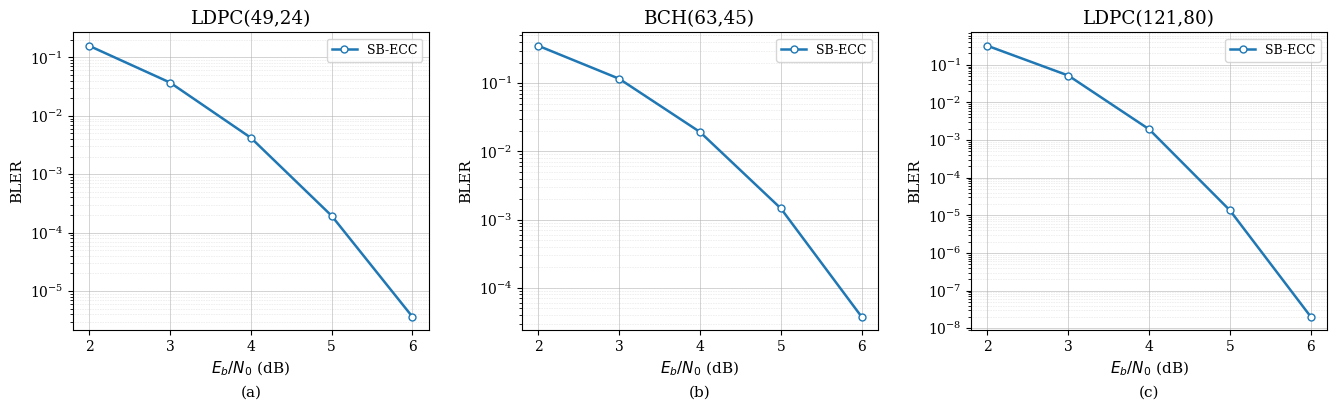


Figures saved:
/content/SB-ECC/figures/SB_ECC_BLER_Comparison.png
/content/SB-ECC/figures/SB_ECC_BLER_Comparison.pdf


In [ ]:
import re
import ast
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/SB-ECC")
LOG_DIR = ROOT / "test_logs"
SAVE_DIR = ROOT / "figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

models = [
    ("LDPC(49,24)", "LDPC49-24_paper.log"),
    ("BCH(63,45)", "BCH63-45_paper.log"),
    ("LDPC(121,80)", "LDPC121-80_paper.log"),
]

NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"
VALUE = (
    rf"(\[[^\]]*\]|"
    rf"np\.float(?:16|32|64)\(\s*{NUMBER}\s*\)|"
    rf"{NUMBER})(?=\s*(?:,|$|#))"
)


def resolve_log_path(filename):
    exact_path = LOG_DIR / filename

    if exact_path.is_file():
        return exact_path

    stem = Path(filename).stem
    suffix = Path(filename).suffix

    candidates = sorted(
        path
        for path in LOG_DIR.glob(f"{stem}*{suffix}")
        if path.is_file()
        and re.fullmatch(
            rf"{re.escape(stem)}(?:\s*\(\d+\))*{re.escape(suffix)}",
            path.name
        )
    )

    if len(candidates) == 1:
        print(f"Reading: {candidates[0]}")
        return candidates[0]

    if len(candidates) > 1:
        raise RuntimeError(
            f"Multiple files match {filename}:\n"
            + "\n".join(str(path) for path in candidates)
            + f"\nRename the intended file to {filename}."
        )

    raise FileNotFoundError(f"Log file not found: {exact_path}")


def parse_last_value(raw):
    clean = re.sub(
        r"np\.float(?:16|32|64)\(\s*([^()]*)\s*\)",
        r"\1",
        raw.strip()
    )

    value = ast.literal_eval(clean)

    if isinstance(value, (list, tuple)):
        if not value:
            raise ValueError("Empty numeric list")
        value = value[-1]

    return float(value)


def parse_bler_log(log_path):
    text = Path(log_path).read_text(
        encoding="utf-8",
        errors="replace"
    )

    summary = {}
    test_records = {}
    supplementary_records = {}

    for line_number, line in enumerate(text.splitlines(), start=1):
        line = line.strip()

        # Summary format:
        # Test FER 2: ... 3: ... 4: ...
        summary_match = re.match(
            r"^Test (?:FER|BLER)\s+",
            line
        )

        if summary_match:
            pairs = re.findall(
                rf"({NUMBER})\s*:\s*({NUMBER})",
                line[summary_match.end():]
            )

            for snr, value in pairs:
                summary[float(snr)] = float(value)

            continue

        record_match = re.match(
            rf"^(Test|PaperReference|Paper)\s+"
            rf"EbN0\s*=\s*({NUMBER})\s*,",
            line
        )

        if not record_match:
            continue

        prefix = record_match.group(1)
        snr = float(record_match.group(2))

        # Prefer exact FER/BLER fields and completed step arrays.
        metric_match = re.search(
            rf"(?:^|,\s*)(?:FER_DDPM|BLER_DDPM|FER|BLER)"
            rf"\s*=\s*{VALUE}",
            line
        )

        # Also support supplemented records with approximate fields.
        if metric_match is None:
            metric_match = re.search(
                rf"(?:^|,\s*)(?:FER_approx|BLER_approx)"
                rf"\s*=\s*{VALUE}",
                line
            )

        if metric_match is None:
            continue

        try:
            value = parse_last_value(metric_match.group(1))

            if prefix == "Test":
                test_records[snr] = value
            else:
                supplementary_records[snr] = value

        except (ValueError, SyntaxError, TypeError, IndexError) as error:
            print(
                f"Cannot parse {Path(log_path).name}, "
                f"line {line_number}: {error}"
            )

    results = dict(supplementary_records)
    results.update(summary)
    results.update(test_records)

    return {
        snr: value
        for snr, value in results.items()
        if np.isfinite(snr)
        and np.isfinite(value)
        and 0 < value <= 1
    }


# Load data
datasets = []

for model_name, filename in models:
    log_path = resolve_log_path(filename)
    results = parse_bler_log(log_path)

    if not results:
        raise ValueError(f"No valid BLER records found in {log_path}")

    points = sorted(results.items())
    datasets.append((model_name, points))

    print(f"\n{model_name}")

    for snr, value in points:
        print(f"Eb/N0={snr:g} dB, BLER={value:.8e}")


# Plot
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
    "savefig.dpi": 300,
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(13.5, 4.3)
)

for idx, (model_name, points) in enumerate(datasets):
    ax = axes[idx]
    x, y = zip(*points)

    ax.semilogy(
        x, y,
        color="tab:blue",
        marker="o",
        markersize=5,
        markerfacecolor="white",
        linewidth=1.8,
        linestyle="-",
        label="SB-ECC"
    )

    ax.set_title(model_name)
    ax.set_xlabel(r"$E_b/N_0$ (dB)")
    ax.set_ylabel("BLER")
    ax.set_xticks([2, 3, 4, 5, 6])
    ax.set_xlim(1.8, 6.2)

    ax.grid(
        True,
        which="major",
        linestyle="-",
        linewidth=0.6,
        alpha=0.65
    )

    ax.grid(
        True,
        which="minor",
        linestyle=":",
        linewidth=0.45,
        alpha=0.5
    )

    ax.legend(loc="best", frameon=True)

    ax.text(
        0.5, -0.21,
        f"({chr(97 + idx)})",
        transform=ax.transAxes,
        ha="center",
        va="center"
    )

plt.tight_layout(w_pad=2.0)

png_path = SAVE_DIR / "SB_ECC_BLER_Comparison.png"
pdf_path = SAVE_DIR / "SB_ECC_BLER_Comparison.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nFigures saved:")
print(png_path)
print(pdf_path)


MacKay(96,48)
Eb/N0=2 dB, BLER=1.71576052e-01
Eb/N0=3 dB, BLER=2.62874681e-02
Eb/N0=4 dB, BLER=1.61164726e-03
Eb/N0=5 dB, BLER=4.20108031e-05
Eb/N0=6 dB, BLER=1.25997742e-06

CCSDS(128,64)
Eb/N0=2 dB, BLER=3.72110172e-01
Eb/N0=3 dB, BLER=7.82146843e-02
Eb/N0=4 dB, BLER=5.34119898e-03
Eb/N0=5 dB, BLER=9.69979803e-05
Eb/N0=6 dB, BLER=1.14997939e-06


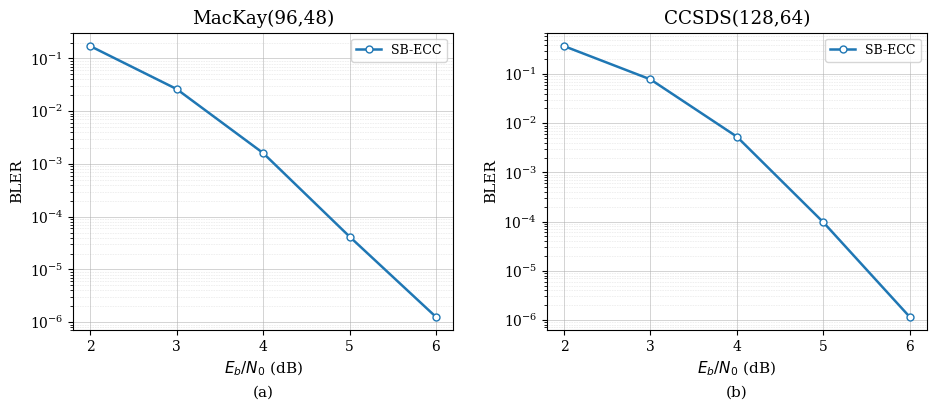


Figures saved:
/content/SB-ECC/figures/SB_ECC_MACKAY_CCSDS_BLER.png
/content/SB-ECC/figures/SB_ECC_MACKAY_CCSDS_BLER.pdf


In [8]:
import re
import ast
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Paths
# ============================================================
ROOT = Path("/content/SB-ECC")
LOG_DIR = ROOT / "test_logs"
SAVE_DIR = ROOT / "figures"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

models = [
    ("MacKay(96,48)", "MACKAY96-48_paper.log"),
    ("CCSDS(128,64)", "CCSDS128-64_paper.log"),
]

NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"

VALUE = (
    rf"(\[[^\]]*\]|"
    rf"np\.float(?:16|32|64)\(\s*{NUMBER}\s*\)|"
    rf"{NUMBER})(?=\s*(?:,|$|#))"
)


# ============================================================
# 2. Locate log files
# ============================================================
def resolve_log_path(filename):

    exact_path = LOG_DIR / filename

    if exact_path.is_file():
        return exact_path

    stem = Path(filename).stem
    suffix = Path(filename).suffix

    candidates = sorted(
        path
        for path in LOG_DIR.glob(f"{stem}*{suffix}")
        if path.is_file()
        and re.fullmatch(
            rf"{re.escape(stem)}(?:\s*\(\d+\))*{re.escape(suffix)}",
            path.name
        )
    )

    if len(candidates) == 1:
        print(f"Reading: {candidates[0]}")
        return candidates[0]

    if len(candidates) > 1:
        raise RuntimeError(
            f"Multiple files match {filename}:\n"
            + "\n".join(str(path) for path in candidates)
        )

    raise FileNotFoundError(
        f"Log file not found: {exact_path}"
    )


# ============================================================
# 3. Parse numeric values
# ============================================================
def parse_last_value(raw):

    clean = re.sub(
        r"np\.float(?:16|32|64)\(\s*([^()]*)\s*\)",
        r"\1",
        raw.strip()
    )

    value = ast.literal_eval(clean)

    if isinstance(value, (list, tuple)):
        if not value:
            raise ValueError("Empty numeric list")
        value = value[-1]

    return float(value)


# ============================================================
# 4. Parse measured BLER / FER
# ============================================================
def parse_bler_log(log_path):

    text = Path(log_path).read_text(
        encoding="utf-8",
        errors="replace"
    )

    summary = {}
    test_records = {}

    for line_number, line in enumerate(
        text.splitlines(), start=1
    ):

        line = line.strip()

        # Summary format:
        # Test FER 2: ... 3: ... 4: ...
        summary_match = re.match(
            r"^Test (?:FER|BLER)\s+",
            line
        )

        if summary_match:

            pairs = re.findall(
                rf"({NUMBER})\s*:\s*({NUMBER})",
                line[summary_match.end():]
            )

            for snr, value in pairs:
                summary[float(snr)] = float(value)

            continue

        # Only actual Test records
        record_match = re.match(
            rf"^Test\s+EbN0\s*=\s*({NUMBER})\s*,",
            line
        )

        if not record_match:
            continue

        snr = float(record_match.group(1))

        # Prefer actual measured FER / BLER fields.
        metric_match = re.search(
            rf"(?:^|,\s*)(?:FER|BLER)\s*=\s*{VALUE}",
            line
        )

        # Support final DDPM step arrays
        if metric_match is None:
            metric_match = re.search(
                rf"(?:^|,\s*)(?:FER_DDPM|BLER_DDPM)"
                rf"\s*=\s*{VALUE}",
                line
            )

        # Support approximate fields
        if metric_match is None:
            metric_match = re.search(
                rf"(?:^|,\s*)(?:FER_approx|BLER_approx)"
                rf"\s*=\s*{VALUE}",
                line
            )

        if metric_match is None:
            continue

        try:
            value = parse_last_value(
                metric_match.group(1)
            )

            test_records[snr] = value

        except (
            ValueError,
            SyntaxError,
            TypeError,
            IndexError
        ) as error:

            print(
                f"Cannot parse {Path(log_path).name}, "
                f"line {line_number}: {error}"
            )

    # Prefer precise Test records
    results = dict(summary)
    results.update(test_records)

    # Exclude PaperReference / Paper records
    return {
        snr: value
        for snr, value in results.items()
        if np.isfinite(snr)
        and np.isfinite(value)
        and 0 < value <= 1
    }


# ============================================================
# 5. Load data
# ============================================================
datasets = []

for model_name, filename in models:

    log_path = resolve_log_path(filename)

    results = parse_bler_log(log_path)

    if not results:
        raise ValueError(
            f"No valid BLER records found in {log_path}"
        )

    points = sorted(results.items())

    datasets.append(
        (model_name, points)
    )

    print(f"\n{model_name}")

    for snr, value in points:
        print(
            f"Eb/N0={snr:g} dB, BLER={value:.8e}"
        )


# ============================================================
# 6. Plot settings
# ============================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
    "savefig.dpi": 300,
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(9.5, 4.3)
)


# ============================================================
# 7. Plot BLER
# ============================================================
for idx, (model_name, points) in enumerate(datasets):

    ax = axes[idx]

    x, y = zip(*points)

    ax.semilogy(
        x, y,
        color="tab:blue",
        marker="o",
        markersize=5,
        markerfacecolor="white",
        linewidth=1.8,
        linestyle="-",
        label="SB-ECC"
    )

    ax.set_title(model_name)

    ax.set_xlabel(r"$E_b/N_0$ (dB)")
    ax.set_ylabel("BLER")

    ax.set_xticks([2, 3, 4, 5, 6])
    ax.set_xlim(1.8, 6.2)

    ax.grid(
        True,
        which="major",
        linestyle="-",
        linewidth=0.6,
        alpha=0.65
    )

    ax.grid(
        True,
        which="minor",
        linestyle=":",
        linewidth=0.45,
        alpha=0.5
    )

    ax.legend(
        loc="best",
        frameon=True
    )

    ax.text(
        0.5, -0.21,
        f"({chr(97 + idx)})",
        transform=ax.transAxes,
        ha="center",
        va="center"
    )

plt.tight_layout(w_pad=2.0)


# ============================================================
# 8. Save figures
# ============================================================
png_path = (
    SAVE_DIR / "SB_ECC_MACKAY_CCSDS_BLER.png"
)

pdf_path = (
    SAVE_DIR / "SB_ECC_MACKAY_CCSDS_BLER.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nFigures saved:")
print(png_path)
print(pdf_path)